\begin{equation*}
Input: X+ϵ → ℜ^{1x8};ϵ \sim η(\mu,σ)
\end{equation*}

\begin{equation*}
Output: Y=X→ ℜ^{1x8}
\end{equation*}

\begin{equation*}
Flujos: F→ ℜ^{1x59}
\end{equation*}

\begin{equation*}
Costos: C→ ℜ^{1x59}
\end{equation*}

\begin{equation*}
 F_{d} \epsilon F → ℜ^{1x8}
\end{equation*}
\begin{equation*}
 F_{w} \epsilon F → ℜ^{1x1}
\end{equation*}
\begin{equation*}
 C_{d} \epsilon C → ℜ^{1x8}
\end{equation*}
\begin{equation*}
 C_{w} \epsilon C → ℜ^{1x1}
\end{equation*}
\begin{equation*}
 loss: 1-\frac{1}{N}∑exp(-\frac{(F_{d}C_{d}+F_{w}C_{w}-YC_{d})^{2}}{2σ^{2}})
\end{equation*}
variables que conozco, X, Y y C lo demás se estima por la red

Cd tiene magnitudes de 1000000, Cw de 5000

In [ ]:
from google.colab import drive
from tensorflow.python.ops.nn_ops import softmax
from keras import backend as k
import numpy as np
from matplotlib.gridspec import GridSpec
from IPython import display
from scipy.optimize import linprog
from sklearn.metrics import mean_squared_error,mean_absolute_error,mean_absolute_percentage_error
import numpy as np
import matplotlib. pyplot as plt
from keras.layers import Activation,Dense,Input,BatchNormalization,Dropout,Conv1D,Flatten,MaxPool1D,Dot,Reshape,Conv2D,Concatenate,ReLU,Lambda,MaxPooling2D,Normalization
import cvxpy as cp
import tensorflow as tf
from keras import Model
from IPython import display
from tensorflow.keras import layers
from tensorflow.keras import regularizers
import warnings
import os
import pandas as pd
import pandas as pd
from IPython import display
path='/content/drive/Shareddrives/red_gas_col/Data/'
from keras.models import Sequential
mse=mean_squared_error
mae=mean_absolute_error
mape=mean_absolute_percentage_error
warnings.filterwarnings("ignore")
#drive.mount('/content/drive')

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Objetivo 1

In [ ]:
from scipy.sparse import coo_matrix, eye, hstack
from tensorflow.keras.callbacks import Callback

def GenW(Data_inf,Data_W,Data_T,Data_C,Data_Dc,Data_sto):
    N = len(Data_inf)
    W = len(Data_W)
    wells = coo_matrix((np.ones(W, ), (Data_W['node'] - 1, np.arange(W))), shape=(N, W))
    P = len(Data_T)
    data = np.concatenate((-1.0 * np.ones(P), np.ones(P)))
    row = pd.concat((Data_T['fnode'] - 1, Data_T['tnode'] - 1))
    col = np.concatenate(2 * [np.arange(P)])

    pipes = coo_matrix((data, (row, col)), shape=(N, P))

    C = len(Data_C)
    data = np.concatenate((-1.0 * np.ones(C), np.ones(C)))
    row = pd.concat((Data_C['fnode'] - 1, Data_C['tnode'] - 1))
    col = np.concatenate(2 * [np.arange(C)])
    comps = coo_matrix((data, (row, col)), shape=(N, C))
    users=hstack(len(Data_Dc.T) * [eye(N)])
    S = len(Data_sto)
    sto = coo_matrix((np.ones(S, ), (Data_sto['node'] - 1, np.arange(S))), shape=(N, S))
    sto = hstack([sto, -1.0 * sto])
    w=(hstack((wells, pipes, comps, users, sto))).toarray()
    return w





def split(F_d,F_O):
    y=F_O
    X_train,X_test,y_train, y_test = train_test_split(F_d,y,test_size=0.2)
    return X_train,X_test,y_train, y_test


def flow(C,li,name,e,initializer):
    #D=Dense(1024,activation='selu',kernel_initializer=initializer)(C)
    D=BatchNormalization()(C)
    D=Dense(len(li),name=name,activation=e,kernel_initializer=initializer)(D)

    return D
def pres(C,li,ls,name,initializer):
    D=BatchNormalization()(C)
    D=Dense(len(li),name=name,activation=custom_activation1(li,ls),kernel_initializer=initializer)(C)
    return D

def Flujos(model,X_test):
    model_B = tf.keras.Model(inputs=model.inputs,outputs=model.get_layer('Flujos').output)
    F=model_B.predict(X_test,verbose=False)
    return F

class custom_activation1:
    def __init__(self, lower_bound, upper_bound):
        self.li=tf.cast(lower_bound, tf.float32)
        self.ls=tf.cast(upper_bound, tf.float32)

    def __call__(self, x):
        x=tf.cast(x, tf.float32)
        x=tf.sigmoid(x)*(self.ls-self.li)+self.li
        return x

    def get_config(self):
        return {
            "lower_bound": self.li,
            "upper_bound": self.ls
        }

    @classmethod
    def from_config(cls, config):
        return cls(**config)


class LRReducer(Callback):
    def __init__(self, epoch_threshold):
        super(LRReducer, self).__init__()
        self.epoch_threshold = epoch_threshold

    def on_epoch_begin(self, epoch, logs=None):
        if epoch in self.epoch_threshold:
            lr = float(self.model.optimizer.lr)
            new_lr = lr * 0.1
            self.model.optimizer.lr.assign(new_lr)


import tensorflow as tf

class WellDense(tf.keras.layers.Layer):
    def __init__(self, well=80.0, **kwargs):
        super(WellDense, self).__init__(**kwargs)
        self.well = tf.Variable(initial_value=well, trainable=False, dtype=tf.float32)
    def call(self, inputs):
        x = inputs
        w = tf.reduce_sum(x, axis=1, keepdims=True)
        w = tf.where(w >= self.well, self.well, w)
        return w
    def get_config(self):
        config = super(WellDense, self).get_config()
        config.update({"well": self.well.numpy()})
        return config
    @classmethod
    def from_config(cls, config):
        return cls(**config)


class RestrictedDense(tf.keras.layers.Layer):
    def __init__(self, initializer, well, units, **kwargs):
        super().__init__(**kwargs)
        self.initializer = initializer
        self.units = units
        self.well = tf.constant(well, dtype=tf.float32)


    def call(self, inputs):
        x, In, fw = inputs
        x = tf.where(x <= 0., 0., x)
        x = tf.where(x <= In, x, In)
        mask = tf.where(tf.reduce_sum(In, axis=-1, keepdims=True) <= self.well, 0.0, 1.0)
        x = x * mask
        return x

    def get_config(self):
        config = super().get_config()
        config.update({
            "initializer": tf.keras.initializers.serialize(self.initializer),
            "well": self.well,
            "units": self.units
        })
        return config
    @classmethod
    def from_config(cls, config):
        config['initializer'] = tf.keras.initializers.deserialize(config['initializer'])
        return cls(**config)

class custom_loss3(tf.keras.losses.Loss):
    def __init__(self, Kt, i, j, Bc, ic, jc, find=6, s=0, name="Wey"):
        super().__init__(name=name)
        self.Kt = Kt
        self.i = i
        self.j = j
        self.Bc = Bc
        self.ic = ic
        self.jc = jc
        self.find = find
        self.s = s
        self.lower_bound = tf.constant(1.0, dtype=tf.float32)
        self.upper_bound = tf.constant(Bc, dtype=tf.float32)

    def call(self, y_true, y_pred):
        f = tf.cast(y_pred[:, :self.find], tf.float32)
        P = tf.cast(y_pred[:, self.find:], tf.float32)
        pi = tf.gather(P, self.i, axis=1)
        pj = tf.gather(P, self.j, axis=1)
        loss = tf.keras.losses.huber(f, tf.sign(pi**2-pj**2)*tf.sqrt(self.Kt*tf.abs(pi**2-pj**2)))

        P_ic = tf.gather(P, self.ic, axis=1)
        P_jc = tf.gather(P, self.jc, axis=1)
        h = self.upper_bound + self.lower_bound
        h1 = self.upper_bound - self.lower_bound
        condition = tf.math.logical_and(P_jc / P_ic >= self.lower_bound, P_jc / P_ic <= self.upper_bound)
        Penalty = tf.reduce_mean(tf.where(condition, 0.0, tf.square((P_jc/P_ic-0.5*h)/h1)))
        return loss + Penalty

    def get_config(self):
        return {
            "Kt": self.Kt,
            "i": self.i,
            "j": self.j,
            "Bc": self.Bc,
            "ic": self.ic,
            "jc": self.jc,
            "find": self.find,
            "s": self.s
        }
    @classmethod
    def from_config(cls, config):
        return cls(**config)



class FixedWeightsConstraint(tf.keras.constraints.Constraint):
    def __init__(self, w):
        self.w = tf.constant(w.T, dtype=tf.float32)  # Asegúrate de que `w` está en el formato correcto antes de convertirlo a un tensor.

    def __call__(self, weights):
        return self.w

    def get_config(self):
        return {"w": self.w.numpy().tolist()}  # Convierte el tensor a lista para la serialización.

    @classmethod
    def from_config(cls, config):
        return cls(w=config["w"])


def mish(x):
    return x*tf.math.tanh(tf.math.softplus(x))
def swish(x):
    return x*tf.sigmoid(x)


def flow_model(path, fd,U1,U2,a,b,c, s=1):
    """
    Builds and compiles a TensorFlow Keras model based on data from an Excel file and additional parameters.

    Parameters:
    - path (str): Path to the Excel file containing the model's data.
    - fd (array-like): Additional flow data for the model.
    - seeds (int): Seed for random number generation for reproducibility.
    - s (int): Mode switch for the model configuration.

    Returns:
    - tensorflow.keras.Model: The compiled Keras model.
    """
    Data_inf = pd.read_excel(path, sheet_name='node.info')
    Data_D = pd.read_excel(path, sheet_name='node.dem')
    Data_Dc = pd.read_excel(path, sheet_name='node.demcost')
    Data_W = pd.read_excel(path, sheet_name='well')
    Data_T = pd.read_excel(path, sheet_name='pipe')
    Data_C = pd.read_excel(path, sheet_name='comp')
    Data_sto = pd.read_excel(path, sheet_name='sto')
    w = GenW(Data_inf, Data_W, Data_T, Data_C, Data_Dc, Data_sto)
    N = w.shape[0]
    initializer = tf.keras.initializers.GlorotNormal()
    In = Input(shape=(N,))
    N1 = N
    x=Dense(U1,'selu',kernel_regularizer=regularizers.L1L2(a,a))(In)
    F = []
    if s == 0:
        Li = np.concatenate((Data_T['Fg_min'].values, [0] * len(Data_C), Data_D['Res'].values * 0.0, Data_D['Ind'].values * 0.0, Data_D['Com'].values * 0.0,
                            Data_D['NGV'].values * 0.0, Data_D['Ref'].values,
                            Data_D['Pet'].values * 0.0, [0] * len(Data_sto.values) * 2))
        Ls = np.concatenate((Data_T['Fg_max'].values, Data_C['fmaxc'].values, fd, Data_D['Ind'].values * 0.0, Data_D['Com'].values * 0.0, Data_D['NGV'].values * 0.0, Data_D['Ref'].values * 0.0, Data_D['Pet'].values * 0.0,
                            (Data_sto['V0'].values - Data_sto['V_max'].values) * 0.0, (Data_sto['Vmax'].values - Data_sto['V0'].values) * 0.0))
        F = []
        F0 = WellDense(well=Data_W['Imax'].values[0], name='F_0')(In)
        F1 = flow(x,Li,'F_1',custom_activation1(Li,Ls),initializer)
        F = Concatenate(name='F')([F0, F1])  # ,F2,F3])

    elif s == 1:
        fdin = len(Data_W['Imin'].values) + \
            len([0] * len(Data_T)) + len([0] * len(Data_C))
        fdfn = len([0] * len(Data_sto.values) * 2) + \
            len(Data_inf['Pmin'].values)
        F0 = WellDense(well=Data_W['Imax'].values[0], name='F_0')(In)
        Li = Data_T['Fg_min'].values
        Ls = Data_T['Fg_max'].values
        F1 =flow(x,Li,'F_1',custom_activation1(Li,Ls),initializer)

        Li = [0] * len(Data_C)
        Ls = Data_C['fmaxc'].values
        F2 = flow(x,Li,'F_2',custom_activation1(Li,Ls),initializer)
        xt=BatchNormalization()(x)
        xt=Dense(N1,'selu',activity_regularizer=regularizers.L1L2(b,b),kernel_initializer=initializer)(xt)
        F3 = RestrictedDense(
            initializer=initializer, well=Data_W['Imax'].values[0], name='F_3', units=len(Data_inf))([xt, In, F0])
        Li=np.concatenate((Data_D['Ind'].values*0.0,Data_D['Com'].values*0.0,Data_D['NGV'].values*0.0,Data_D['Ref'].values*0.0,
                        Data_D['Pet'].values*0.0,[0]*len(Data_sto.values)*2))
        Ls=np.concatenate((Data_D['Ind'].values*0.0,Data_D['Com'].values*0.0,Data_D['NGV'].values*0.0,Data_D['Ref'].values*0.0,Data_D['Pet'].values*0.0,
                    (Data_sto['V0'].values-Data_sto['V_max'].values)*0.0,(Data_sto['Vmax'].values-Data_sto['V0'].values)*0.0))
        F4=flow(In,Li,'F_4',custom_activation1(Li,Ls),initializer)
        F = Concatenate(name='F')([F0, F1, F2, F3, F4])

    Out1=Dense(units=w.shape[0],use_bias=False,kernel_constraint=FixedWeightsConstraint(w),name='Bal')(F)

    Kt=tf.constant(Data_T['Kij'].values,dtype=tf.float32)
    i=Data_T['fnode'].values-1
    j=Data_T['tnode'].values-1
    ftin=len(Data_W)
    ftfn=len(Data_T)
    f=F[:,ftin:ftfn+ftin]
    Li=Data_inf['Pmin'].values
    Ls=Data_inf['Pmax'].values
    x1=Dense(U2,'sigmoid',kernel_regularizer=regularizers.L1L2(c,c),kernel_initializer=initializer)(In)#
    x1=BatchNormalization()(x1)
    ib=Data_C['fnode'].values-1
    jb=Data_C['tnode'].values-1
    P =pres(x1,Li,Ls,'P',initializer)

    Out2 = Concatenate(name='Wey')([f, P])
    Out3 = P

    Bc = Data_C['ratio'].values

    model = Model(In, [Out1, Out2])
    model.compile(loss={'Bal': 'huber', 'Wey': custom_loss3(Kt,i,j,Bc,ib,jb,ftfn)},
                  optimizer=tf.keras.optimizers.Adafactor(1e-2), loss_weights=[0.5, 0.5])
    return model

import time
from keras.callbacks import Callback
class TimeHistory(Callback):
    def on_train_begin(self, logs=None):
        self.times = []

    def on_epoch_begin(self, epoch, logs=None):
        self.epoch_time_start = time.time()

    def on_epoch_end(self, epoch, logs=None):
        self.times.append(time.time() - self.epoch_time_start)
import pandas as pd
import scipy.io as sio
import os
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler,StandardScaler
def EvalBalance(FT,W,X):
    aux1=[]
    aux2=[]
    for i in range(len(FT[0])):
        aux1.append(mape(X[i],FT[0][i]@W.T))
        aux2.append(mape(X[i],FT[1][i]@W.T))
    return[aux1,aux2]
def EvalWeymouth(X,Y):
    aux1=[]
    aux2=[]
    for i in range(len(X[0])):
        aux1.append(mape(X[0][i],Y[0][i]))
        aux2.append(mape(X[1][i],Y[1][i]))
    return[aux1,aux2]
def EvalCost(X,Y):
    aux1=[]
    for i in range(len(X)):
        aux1.append(Y[i] - X[i])
    return aux1
import numpy as np

def dividir_datos(array, indice_test):
    """
    Divide un array en conjuntos de entrenamiento y prueba basado en un índice dado y
    reorganiza el conjunto de entrenamiento a una nueva forma.

    Parámetros:
    - array: Array de entrada con dimensiones (10, 100, 8).
    - indice_test: Índice del sub-array a usar como conjunto de prueba.
a
    Retorna:
    - X_train_reshaped: Array con los datos de entrenamiento reorganizados.
    - X_test: Array con los datos de prueba.
    """
    # Verificar que el índice esté en el rango permitido
    if indice_test < 0 or indice_test >= array.shape[0]:
        raise ValueError("El índice debe estar entre 0 y 9.")

    # Usar el índice para seleccionar el conjunto de prueba y el resto para entrenamiento
    X_test = array[indice_test]
    X_train = np.delete(array, indice_test, axis=0)

    # Cambiar la forma de X_train de (9, 100, 8) a (900, 8)
    X_train_reshaped = np.concatenate(X_train)
    return X_train_reshaped, X_test

In [ ]:
DataSol=[]

[0.13110626029974662] [0.8726608069841181] [0.0]
0.13110626029974662


(1.2, 4.8)

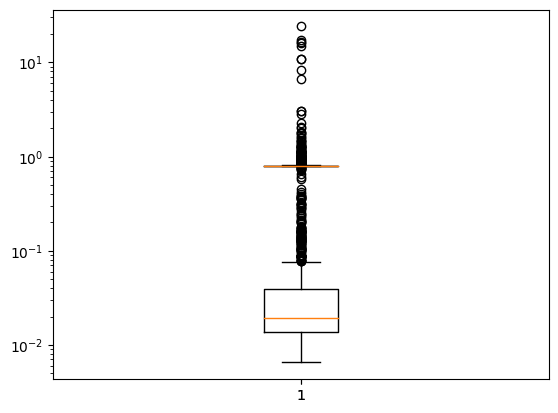

In [ ]:
#8: U1=2048,U2=2048,a=1e-4,b=1e-4,c=0
#9: U1=64,U2=2048,a=1e-4,b=1e-4,c=1e-4
#10: U1=64,U2=2048,a=1e-4,b=1e-4,c=1e-4
#11:U1=64,U2=2048,a=1e-4,b=1e-4,c=1e-4
#12: U1=512,U2=1024,a=1e-4,b=1e-4,c=0
#14: U1=256,U2=2048,a=1e-3,b=1e-4,c=1e-4
#10-12
ajus=[0.0,-2.2,-3.8,-5.1,-6.2,-7.1,-7.9,-8.6,-32.8]
lr_reducer = LRReducer(epoch_threshold=[330,480,570])
nodos=18
im=nodos-8

N=20000
path='/content/drive/Shareddrives/red_gas_col/'
if nodos==18:
    ajusts=ajus[-1]
    path=path+'ng_caseCol_'+str(nodos)+'.xlsx'
else:
    ajusts=ajus[nodos-8]
    path=path+'ng_case'+str(nodos)+'.xlsx'
Data_D=pd.read_excel(path,sheet_name='node.dem')
min=Data_D.values.sum(axis=1).min()
max=Data_D.values.sum(axis=1).max()
X_train,X_test=train_test_split(np.random.uniform(min,max-ajusts,(N,nodos)), shuffle=True,test_size=0.2)
fd = np.array(X_train).max(axis=0)

s=1
if im in [1,2,3,5]:
    model = flow_model(path, fd,U1=64,U2=2048,a=1e-4,b=1e-4,c=1e-4, s=s)
    model.load_weights('/content/drive/Shareddrives/red_gas_col/Prueba/Data/model'+str(nodos)+'.h5')
elif im in [4,7]:
    model= flow_model(path, fd,U1=512,U2=1024,a=1e-4,b=1e-4,c=0, s=s)
    model.load_weights('/content/drive/Shareddrives/red_gas_col/Prueba/Data/model'+str(nodos)+'.h5')
elif im == 0:
    model= flow_model(path, fd,U1=2048,U2=2048,a=1e-4,b=1e-4,c=0, s=s)
    model.load_weights('/content/drive/Shareddrives/red_gas_col/Prueba/Data/model'+str(nodos)+'.h5')
elif im == 6:
    model= flow_model(path, fd,U1=256,U2=256,a=0,b=1e-4,c=1e-4, s=s)
    model.load_weights('/content/drive/Shareddrives/red_gas_col/Prueba/Data/model'+str(nodos)+'.h5')
else:
    model= flow_model(path, fd,U1=1024,U2=1024,a=1e-4,b=1e-4,c=1, s=s)
    model.load_weights('/content/drive/Shareddrives/red_gas_col/Prueba/Data/modelCol.h5')


#history=model.fit(X_train,X_train,epochs=600,validation_split=0.2,verbose=True,batch_size=256,callbacks=[lr_reducer])
Data_inf=pd.read_excel(path,sheet_name='node.info')

Data_Dc=pd.read_excel(path,sheet_name='node.demcost')
Data_W=pd.read_excel(path,sheet_name='well')
Data_T=pd.read_excel(path,sheet_name='pipe')
Data_C=pd.read_excel(path,sheet_name='comp')
Data_sto=pd.read_excel(path,sheet_name='sto')
Cost=np.concatenate((Data_W['Cg'].values,Data_T['C_O'].values,Data_C['costc'],Data_Dc['al_Res'].values,
                Data_Dc['al_Ind'].values,Data_Dc['al_Com'].values,Data_Dc['al_NGV'].values,Data_Dc['al_Ref'].values,Data_Dc['al_Pet'].values,
                    Data_sto['C_S+'].values-Data_sto['C_V'].values,-1*(Data_sto['C_S-']-Data_sto['C_V']).values,Data_sto['C_V'].values)).reshape(-1,1)
cost=Cost
w=GenW(Data_inf,Data_W,Data_T,Data_C,Data_Dc,Data_sto)
X_test = DataSol[8]#np.random.uniform(min,max-ajusts,(1000,nodos))
Wey=[]
Bal=[]
Com=[]
model_A = tf.keras.Model(inputs=model.inputs,outputs=model.get_layer('F').output)
model_B= tf.keras.Model(inputs=model.inputs,outputs=model.get_layer('P').output)
Fe=model_A.predict(np.array(X_test),verbose=False)
Pe=model_B.predict(np.array(X_test),verbose=False)
i=Data_T['fnode'].values.astype(int)-1
j=Data_T['tnode'].values.astype(int)-1
CK=Data_T['Kij'].values.reshape(-1,)
nod=len(Data_inf)
Fte=Fe[:,1:1+len(Data_T)]
Pie=Pe[:,i]
Pje=Pe[:,j]
Pte=np.sign(Pie**2-Pje**2)*np.sqrt(CK*np.abs(Pie**2-Pje**2))
from sklearn.metrics import mean_squared_error,mean_absolute_error,mean_absolute_percentage_error
mape=mean_absolute_percentage_error
Wey.append(mape(Fte,Pte))
Bal.append(mape(X_test,(Fe@w.T)))
ic = Data_C['fnode'].values.astype(int) - 1
jc = Data_C['tnode'].values.astype(int) - 1
Bc = Data_C['ratio'].values
are = np.round(Pe[:, jc] / Pe[:, ic], 3)
ind1 = np.unique(np.concatenate((np.where(~(are[:, 0] <= Bc[0]) | ~(are[:, 0] >= 1.0))[
    0], np.where(~(are[:, 1] <= Bc[1]) | ~(are[:, 1] >= 1.0))[0])))
re1 = np.zeros(X_test.shape[0])
if len(ind1) != 0:
    re1[ind1] = 100
Com.append(mse(np.zeros(re1.shape),re1))
print(Bal,Wey,Com)

Wey=[]
Bal=[]
for i in range(len(Fte)):
    Wey.append(mape(Fte[i],Pte[i]))
    Bal.append(mape(X_test[i],(Fe[i]@w.T)))
plt.boxplot(np.array(Wey))
plt.boxplot(np.array(Bal))
plt.yscale('log')
Wey=np.array(Wey)
Bal=np.array(Bal)
print(mape(X_test,(Fe@w.T)))
Bal[Bal>=1].shape[0]/Bal.shape[0]*100,Wey[Wey>=1].shape[0]/Wey.shape[0]*100

In [ ]:
#DataSol.append(X_test)

In [ ]:
DataSol[0].shape

(1000, 8)

In [ ]:
i=8
np.save('/content/drive/Shareddrives/red_gas_col/Prueba/Data/Test/Red'+str(i)+'.npy',DataSol[i])

In [ ]:
#11: 2048,1024,'gelu','selu','gelu',1e-4,1e-4,1e-1,
ajus=[0.0,-2.2,-3.8,-5.1,-6.2,-7.1,-7.9,-8.6,-32.8]
lr_reducer = LRReducer(epoch_threshold=[330,480,570])
nodos=18
ajusts=ajus[-1]
N=20000
path='/content/drive/Shareddrives/red_gas_col/'
path=path+'ng_caseCol_'+str(nodos)+'.xlsx'
ajusts=ajus[-1]
Data_D=pd.read_excel(path,sheet_name='node.dem')
min=Data_D.values.sum(axis=1).min()
max=Data_D.values.sum(axis=1).max()
X_train,X_test=train_test_split(np.random.uniform(min,max-ajusts,(N,nodos)), shuffle=True,test_size=0.2)
fd = np.array(X_train).max(axis=0)
model=flow_model(path, fd,2048,1024,1e-4,1e-4,1e-1, s=1)
history=model.fit(X_train,X_train,epochs=6,validation_split=0.2,verbose=True,batch_size=256,callbacks=[lr_reducer])

Epoch 1/6
50/50 [==============================] - 8s 51ms/step - loss: 329.0591 - Bal_loss: 114.8056 - Wey_loss: 401.7855 - val_loss: 312.2755 - val_Bal_loss: 101.6942 - val_Wey_loss: 381.5471
Epoch 2/6
50/50 [==============================] - 2s 41ms/step - loss: 271.7013 - Bal_loss: 90.7855 - Wey_loss: 313.0690 - val_loss: 276.8363 - val_Bal_loss: 92.7050 - val_Wey_loss: 323.1975
Epoch 3/6
50/50 [==============================] - 2s 41ms/step - loss: 236.7062 - Bal_loss: 77.7834 - Wey_loss: 259.2773 - val_loss: 234.5638 - val_Bal_loss: 83.6771 - val_Wey_loss: 250.8623
Epoch 4/6
50/50 [==============================] - 3s 64ms/step - loss: 210.1762 - Bal_loss: 67.0697 - Wey_loss: 220.3017 - val_loss: 210.0633 - val_Bal_loss: 86.1406 - val_Wey_loss: 202.8798
Epoch 5/6
50/50 [==============================] - 3s 54ms/step - loss: 185.7811 - Bal_loss: 56.2490 - Wey_loss: 185.8746 - val_loss: 184.5461 - val_Bal_loss: 72.4107 - val_Wey_loss: 169.1210
Epoch 6/6
50/50 [=====================

In [ ]:

from scipy.io import savemat, loadmat
loadmat('/content/Input191.mat')['inputs'].shape

(190, 9)

In [ ]:
!pip install wandb -Uq
import wandb
wandb.login()


True

In [ ]:

sweep_config = {
    'method': 'grid',
    'metric': {
        'name': 'val_loss',
        'goal': 'minimize'
    },
    'parameters': {
        'U1': {
            'values':[64,128,256,512,1024,2048]
        },
        'U2': {
            'values':[64,128,256,512,1024,2048]
        },

        'a': {
             'values': [1e0,0,1e-1,1e-2,1e-3,1e-4]
        },
       'b': {
             'values': [1e0,0,1e-1,1e-2,1e-3,1e-4]
        },
       'c': {
             'values': [1e0,0,1e-1,1e-2,1e-3,1e-4]
        }
    },
    'run_cap':
}
sweep_id = wandb.sweep(sweep_config, project="Red 18 Nodos")

Create sweep with ID: jxnpu6o7
Sweep URL: https://wandb.ai/daprosero/Red%2018%20Nodos/sweeps/jxnpu6o7


In [ ]:
from wandb.keras import WandbCallback
class CustomWandbCallback(Callback):
    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        wandb.log(logs)
def train():
    wandb.init()


    # Accede a los hiperparámetros con wandb.config
    config = wandb.config
    ajus=[0.0,-2.2,-3.8,-5.1,-6.2,-7.1,-7.9,-8.6,-32.8]
    lr_reducer = LRReducer(epoch_threshold=[330,480,570])
    nodos=18
    ajusts=ajus[-1]
    N=20000
    path='/content/drive/Shareddrives/red_gas_col/'
    path=path+'ng_caseCol_'+str(nodos)+'.xlsx'
    ajusts=ajus[-1]
    Data_D=pd.read_excel(path,sheet_name='node.dem')
    min=Data_D.values.sum(axis=1).min()
    max=Data_D.values.sum(axis=1).max()
    X_train,X_test=train_test_split(np.random.uniform(min,max-ajusts,(N,nodos)), shuffle=True,test_size=0.2)
    fd = np.array(X_train).max(axis=0)
    model=flow_model(path, fd,config.U1,config.U2,config.a,config.b,config.c, s=1)
    history=model.fit(X_train,X_train,epochs=600,verbose=False,validation_split=0.2,batch_size=256,callbacks=[CustomWandbCallback(),lr_reducer])
wandb.agent(sweep_id, train)

wandb: Agent Starting Run: sbk4t8ty with config:
wandb: 	U1: 256
wandb: 	U2: 1024
wandb: 	a: 1
wandb: 	b: 0.1
wandb: 	c: 0.001


Bal_loss,█▃▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
Wey_loss,█▃▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
loss,█▄▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val_Bal_loss,█▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val_Wey_loss,█▃▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val_loss,█▄▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
Bal_loss,55.48697
Wey_loss,0.03744
loss,27.81798
val_Bal_loss,55.51695
val_Wey_loss,0.02915


wandb: Sweep Agent: Waiting for job.
wandb: Job received.
wandb: Agent Starting Run: h2e6k3pl with config:
wandb: 	U1: 1024
wandb: 	U2: 256
wandb: 	a: 0.01
wandb: 	b: 0.0001
wandb: 	c: 1


Bal_loss,█▆▄▄▃▃▃▃▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
Wey_loss,█▆▅▅▃▃▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
loss,█▄▃▃▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val_Bal_loss,█▆▄▃▃▃▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val_Wey_loss,█▅▅▅▄▃▂▂▂▂▂▂▂▁▂▃▂▂▁▃▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val_loss,█▄▃▃▂▂▂▂▂▂▂▂▂▁▁▂▁▁▁▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
Bal_loss,0.95673
Wey_loss,3.28535
loss,11.5334
val_Bal_loss,0.92044
val_Wey_loss,4.53487


wandb: Agent Starting Run: nxars3sv with config:
wandb: 	U1: 1024
wandb: 	U2: 512
wandb: 	a: 0
wandb: 	b: 0.1
wandb: 	c: 0


Bal_loss,█▄▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
Wey_loss,█▅▃▃▂▂▂▂▂▂▂▂▂▂▂▁▂▂▂▂▁▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
loss,█▅▃▃▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val_Bal_loss,█▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val_Wey_loss,█▅▃▂▂▂▂▁▁▂▁▁▁▁▁▁▁▂▁▁▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val_loss,█▄▂▂▂▂▂▁▁▂▁▁▁▁▁▁▁▂▁▁▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
Bal_loss,55.82222
Wey_loss,1.94385
loss,35.72999
val_Bal_loss,55.69087
val_Wey_loss,5.63003


... (15 outputs left out)

Bal_loss,█▆▄▃▃▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
Wey_loss,█▄▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
loss,█▅▃▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val_Bal_loss,█▅▄▃▃▂▂▁▁▁▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val_Wey_loss,█▅▃▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val_loss,█▅▃▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
Bal_loss,0.32448
Wey_loss,0.12733
loss,8.52139
val_Bal_loss,0.34559
val_Wey_loss,0.12634


wandb: Agent Starting Run: kazqythi with config:
wandb: 	U1: 1024
wandb: 	U2: 1024
wandb: 	a: 0.0001
wandb: 	b: 0.0001
wandb: 	c: 1


Bal_loss,█▅▃▃▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
Wey_loss,█▅▃▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
loss,█▄▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val_Bal_loss,█▄▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val_Wey_loss,█▅▃▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val_loss,█▄▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
Bal_loss,0.39098
Wey_loss,0.04577
loss,7.88486
val_Bal_loss,0.35078
val_Wey_loss,0.04204


wandb: Sweep Agent: Waiting for job.
wandb: Sweep Agent: Exiting.


In [ ]:
# Data_inf=pd.read_excel(path,sheet_name='node.info')

# Data_Dc=pd.read_excel(path,sheet_name='node.demcost')
# Data_W=pd.read_excel(path,sheet_name='well')
# Data_T=pd.read_excel(path,sheet_name='pipe')
# Data_C=pd.read_excel(path,sheet_name='comp')
# Data_sto=pd.read_excel(path,sheet_name='sto')
# Cost=np.concatenate((Data_W['Cg'].values,Data_T['C_O'].values,Data_C['costc'],Data_Dc['al_Res'].values,
#                 Data_Dc['al_Ind'].values,Data_Dc['al_Com'].values,Data_Dc['al_NGV'].values,Data_Dc['al_Ref'].values,Data_Dc['al_Pet'].values,
#                     Data_sto['C_S+'].values-Data_sto['C_V'].values,-1*(Data_sto['C_S-']-Data_sto['C_V']).values,Data_sto['C_V'].values)).reshape(-1,1)
# cost=Cost
# w=GenW(Data_inf,Data_W,Data_T,Data_C,Data_Dc,Data_sto)
# X_test = np.random.uniform(min,max-ajusts,(10000,nodos))
# Wey=[]
# Bal=[]
# Com=[]
# model_A = tf.keras.Model(inputs=model.inputs,outputs=model.get_layer('F').output)
# model_B= tf.keras.Model(inputs=model.inputs,outputs=model.get_layer('P').output)
# Fe=model_A.predict(np.array(X_test),verbose=False)
# Pe=model_B.predict(np.array(X_test),verbose=False)
# i=Data_T['fnode'].values.astype(int)-1
# j=Data_T['tnode'].values.astype(int)-1
# CK=Data_T['Kij'].values.reshape(-1,)
# nod=len(Data_inf)
# Fte=Fe[:,1:1+len(Data_T)]
# Pie=Pe[:,i]
# Pje=Pe[:,j]
# Pte=np.sign(Pie**2-Pje**2)*np.sqrt(CK*np.abs(Pie**2-Pje**2))
# from sklearn.metrics import mean_squared_error,mean_absolute_error,mean_absolute_percentage_error
# mape=mean_absolute_percentage_error
# Wey.append(mape(Fte,Pte))
# Bal.append(mape(X_test,(Fe@w.T)))
# ic = Data_C['fnode'].values.astype(int) - 1
# jc = Data_C['tnode'].values.astype(int) - 1
# Bc = Data_C['ratio'].values
# are = np.round(Pe[:, jc] / Pe[:, ic], 4)
# ind1 = np.unique(np.concatenate((np.where(~(are[:, 0] <= Bc[0]) | ~(are[:, 0] >= 1.0))[
#     0], np.where(~(are[:, 1] <= Bc[1]) | ~(are[:, 1] >= 1.0))[0])))
# re1 = np.zeros(X_test.shape[0])
# if len(ind1) != 0:
#     re1[ind1] = 0.1
# Com.append(mse(np.zeros(re1.shape),re1))
# print(Bal,Wey,Com)
# Wey=[]
# Bal=[]
# for i in range(len(Fte)):
#     Wey.append(mape(Fte[i],Pte[i]))
#     Bal.append(mape(X_test[i],(Fe[i]@w.T)))
# plt.boxplot(np.array(Wey))
# plt.boxplot(np.array(Bal))
# plt.yscale('log')
# Wey=np.array(Wey)
# Bal=np.array(Bal)
# print(mape(X_test,(Fe@w.T)))
# Bal[Bal>=1].shape[0]/Bal.shape[0]*100,Wey[Wey>=1].shape[0]/Wey.shape[0]*100

In [ ]:
# for i in range(len(Wey)):
#     Wey[i]=Wey[i]+[np.concatenate(Wey).max()]*(100-np.array(Wey[i]).shape[0])
# Wey=np.array(Wey)
# Me=Wey.mean(-1)
# Var=Wey.var(-1)
# # # Crear el DataFrame intercalando medias y varianzas
# # data = np.empty((len(Me)*2,), dtype=float)
# # data[0::2] = Me  # Valores de media en posiciones pares
# # data[1::2] = Var  # Valores de varianza en posiciones impares

# # # Calcular la media de las medias y la varianza de las medias
# # media_de_medias = Me.mean()
# # varianza_de_medias = Me.var()
# # # Añadir estos valores al final del DataFrame como columnas separadas
# # try:
# #     df1=pd.read_excel('/content/drive/Shareddrives/red_gas_col/Prueba/Data/Test/Test2.xlsx')
# #     df = pd.DataFrame(data.reshape(1, -1), )
# #     df['Media de Medias'] = media_de_medias
# #     df['Varianza de Medias'] = varianza_de_medias
# #     df=pd.concat((df1,df))
# #     df.to_excel('/content/drive/Shareddrives/red_gas_col/Prueba/Data/Test/Test2.xlsx',index=False)
# # except:
# #     df = pd.DataFrame(data.reshape(1, -1),)
# #     df['Media de Medias'] = media_de_medias
# #     df['Varianza de Medias'] = varianza_de_medias
# #     df.to_excel('/content/drive/Shareddrives/red_gas_col/Prueba/Data/Test/Test2.xlsx',index=False)